# Module 2: Tokenization and byte-pair encoding
Companion to `docs/02_tokenization_bpe.html`. We build a byte-level BPE tokenizer from scratch (Sennrich et al. 2016; GPT-2 variant),
train it on Shakespeare, and check it against OpenAI's `tiktoken` to prove it matches GPT-2's tokenizer exactly.
Runs on CPU in about two minutes.

In [1]:
import os, urllib.request
from collections import Counter
import matplotlib.pyplot as plt
import tiktoken

os.makedirs("data", exist_ok=True)
path = "data/tinyshakespeare.txt"
if not os.path.exists(path):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt", path)
text = open(path).read()
cut = int(len(text) * 0.9)
train_text, test_text = text[:cut], text[cut:]
print(f"{len(text):,} characters; train {len(train_text):,} / test {len(test_text):,}")

1,115,394 characters; train 1,003,854 / test 111,540


## 1. Why not just characters or words?
Both extremes have a cost. Count them on Shakespeare:

In [2]:
words = text.split()
types = Counter(words)
print("characters:", len(text))
print("whitespace-separated words:", len(words))
print("distinct word forms:", len(types))
print("word forms seen exactly once:", sum(1 for c in types.values() if c == 1))

characters: 1115394
whitespace-separated words: 202651
distinct word forms: 25670
word forms seen exactly once: 14919


- **Characters/bytes:** tiny vocabulary (256), but sequences are ~5x longer, and attention cost grows with the square of length.
- **Words:** short sequences, but a huge vocabulary with a long tail of rare forms (many seen once), and anything unseen becomes `<unk>`.
- **Subwords (BPE):** frequent words are single tokens, rare words split into reusable pieces, and nothing is ever unknown.

## 2. The algorithm, in about 50 lines
Training: split the text into pieces (pre-tokenization), start from single bytes, and repeatedly merge the most frequent adjacent pair into a new token.
Encoding: split a new text the same way and apply the merges, earliest-learned first. Decoding: concatenate the bytes of each token.
The code below lives in `tools/module02/bpe_core.py` and is pasted here so the notebook is standalone.

In [3]:
import regex as re
from collections import Counter

# GPT-2's pre-tokenization pattern: contractions, letters, digits, punctuation, whitespace
GPT2_PAT = re.compile(r"""'(?:[sdmt]|ll|ve|re)| ?\p{L}+| ?\p{N}+| ?[^\s\p{L}\p{N}]+|\s+(?!\S)|\s+""")


def merge_pair(toks, pair, new):
    """Replace every adjacent occurrence of `pair` in the token list with `new`."""
    out, i = [], 0
    while i < len(toks):
        if i < len(toks) - 1 and (toks[i], toks[i + 1]) == pair:
            out.append(new)
            i += 2
        else:
            out.append(toks[i])
            i += 1
    return out


def train_bpe(text, vocab_size, pat=GPT2_PAT):
    """Learn byte-level BPE merges. Returns ranks: dict mapping token bytes -> id.
    Ids 0..255 are the single bytes; every merge adds one new id."""
    word_freq = Counter(pat.findall(text))                      # pre-tokenize, count unique pieces
    seqs = {w: [bytes([b]) for b in w.encode()] for w in word_freq}
    ranks = {bytes([i]): i for i in range(256)}
    while len(ranks) < vocab_size:
        pairs = Counter()
        for w, toks in seqs.items():
            for a, b in zip(toks, toks[1:]):
                pairs[a, b] += word_freq[w]
        if not pairs:
            break
        (a, b), _ = pairs.most_common(1)[0]                     # most frequent adjacent pair
        new = a + b
        ranks[new] = len(ranks)
        for w in seqs:
            seqs[w] = merge_pair(seqs[w], (a, b), new)
    return ranks


def encode_piece(piece, ranks):
    """BPE-encode one pre-tokenized piece: repeatedly merge the adjacent pair
    whose concatenation has the lowest id (= was learned earliest)."""
    parts = [bytes([b]) for b in piece]
    while len(parts) > 1:
        best = None
        for i in range(len(parts) - 1):
            r = ranks.get(parts[i] + parts[i + 1])
            if r is not None and (best is None or r < best[0]):
                best = (r, i)
        if best is None:
            break
        i = best[1]
        parts[i:i + 2] = [parts[i] + parts[i + 1]]
    return [ranks[p] for p in parts]


def encode(text, ranks, pat=GPT2_PAT):
    return [i for piece in pat.findall(text) for i in encode_piece(piece.encode(), ranks)]


def decode(ids, ranks):
    inv = {i: t for t, i in ranks.items()}
    return b"".join(inv[i] for i in ids).decode("utf-8", errors="replace")

## 3. Trace it on the toy example from the paper
Sennrich et al. use the corpus `low`(5) `lower`(2) `newest`(6) `widest`(3) with an end-of-word marker. Watch the merges form.

In [4]:
def toy_bpe(words, n_merges):
    seqs = {w: list(w) + ["</w>"] for w in words}
    for step in range(n_merges):
        pairs = Counter()
        for w, s in seqs.items():
            for a, b in zip(s, s[1:]):
                pairs[a, b] += words[w]
        (a, b), n = pairs.most_common(1)[0]
        seqs = {w: merge_pair(s, (a, b), a + b) for w, s in seqs.items()}
        print(f"merge {step+1}: {a} + {b} -> {a+b}  ({n}x)    ", {w: " ".join(s) for w, s in seqs.items()})

toy_bpe({"low": 5, "lower": 2, "newest": 6, "widest": 3}, 7)

merge 1: e + s -> es  (9x)     {'low': 'l o w </w>', 'lower': 'l o w e r </w>', 'newest': 'n e w es t </w>', 'widest': 'w i d es t </w>'}
merge 2: es + t -> est  (9x)     {'low': 'l o w </w>', 'lower': 'l o w e r </w>', 'newest': 'n e w est </w>', 'widest': 'w i d est </w>'}
merge 3: est + </w> -> est</w>  (9x)     {'low': 'l o w </w>', 'lower': 'l o w e r </w>', 'newest': 'n e w est</w>', 'widest': 'w i d est</w>'}
merge 4: l + o -> lo  (7x)     {'low': 'lo w </w>', 'lower': 'lo w e r </w>', 'newest': 'n e w est</w>', 'widest': 'w i d est</w>'}
merge 5: lo + w -> low  (7x)     {'low': 'low </w>', 'lower': 'low e r </w>', 'newest': 'n e w est</w>', 'widest': 'w i d est</w>'}
merge 6: n + e -> ne  (6x)     {'low': 'low </w>', 'lower': 'low e r </w>', 'newest': 'ne w est</w>', 'widest': 'w i d est</w>'}
merge 7: ne + w -> new  (6x)     {'low': 'low </w>', 'lower': 'low e r </w>', 'newest': 'new est</w>', 'widest': 'w i d est</w>'}


`est</w>` appears first, so the frequent suffix `-est` becomes one unit that `newest` and `widest` share, while `lower` still falls back to `low` + `e` + `r`.

## 4. Train on Shakespeare
Pre-tokenize, then learn 768 merges (vocabulary 1,024). Pure Python, about a minute.

In [5]:
import time
t0 = time.time()
ranks = train_bpe(train_text, 1024)
print(f"trained in {time.time()-t0:.0f}s; vocab = {len(ranks)}")
inv = {i: t for t, i in ranks.items()}
print("first merges :", [inv[i].decode(errors="replace") for i in range(256, 276)])
print("late merges  :", [inv[i].decode(errors="replace") for i in range(1000, 1010)])

trained in 60s; vocab = 1024
first merges : [' t', 'he', ' a', 'ou', ' s', ' m', 'in', ' w', 're', 'ha', ' the', 'nd', ' b', 'is', 'or', ' f', 'er', 'll', 'it', 'on']
late merges  : [' comes', 'ought', ' lords', 'ious', 'ont', 'ittle', 'atch', 'EY', 'che', ' gri']


The first merges are the most frequent English bigrams (`' t'`, `'he'`, `' a'`), then whole words (`' the'`); late merges are rarer fragments. The vocabulary is a frequency-ordered record of the training text.

## 5. Encode, decode, and why nothing is ever unknown

In [6]:
sample = "Romeo, Romeo! wherefore art thou Romeo?"
ids = encode(sample, ranks)
print(ids)
print([inv[i].decode() for i in ids])
assert decode(ids, ranks) == sample

weird = "🦜 龍 naïve café"          # characters never seen in Shakespeare
ids = encode(weird, ranks)
print(len(weird), "chars ->", len(ids), "tokens (falls back to bytes):", ids)
assert decode(ids, ranks) == weird

[82, 348, 111, 44, 750, 111, 33, 721, 555, 738, 343, 750, 111, 63]
['R', 'ome', 'o', ',', ' Rome', 'o', '!', ' where', 'fore', ' art', ' thou', ' Rome', 'o', '?']
14 chars -> 18 tokens (falls back to bytes): [240, 159, 166, 156, 32, 233, 190, 141, 281, 97, 195, 175, 294, 277, 97, 102, 195, 169]


Any string round-trips, because the base alphabet is all 256 bytes. There is no `<unk>` in byte-level BPE.

## 6. Check against the real thing
`tiktoken` ships the actual GPT-2 and GPT-4 (`cl100k_base`) vocabularies. Our `encode` only needs a `{token bytes: id}` dictionary, so we can feed it OpenAI's.

In [7]:
import regex
tests = [train_text[:20000], "Hello, world! I'm testing 12345 numbers.\n\n  indented   spaces",
         "🦜 龍 zxqvkj naïve café", "def f(x):\n    return x**2  # square",
         "a  \n\n  b   \t trailing   ", "line1\n\n\nline2   ", "It's DON'T we'll   I'M"]

gpt2 = tiktoken.get_encoding("gpt2")
for t in tests:
    assert encode(t, gpt2._mergeable_ranks) == gpt2.encode(t)
print("our encoder == tiktoken GPT-2 on all tests")

cl = tiktoken.get_encoding("cl100k_base")
cl_pat = regex.compile(cl._pat_str)          # GPT-4 uses a different pre-tokenization pattern
for t in tests:
    assert encode(t, cl._mergeable_ranks, cl_pat) == cl.encode(t)
print("our encoder == tiktoken cl100k_base on all tests")
print("GPT-2 vocab:", gpt2.n_vocab, "= 256 bytes + 50,000 merges + 1 special token")

our encoder == tiktoken GPT-2 on all tests


our encoder == tiktoken cl100k_base on all tests
GPT-2 vocab: 50257 = 256 bytes + 50,000 merges + 1 special token


The two vocabularies differ in the merge table and in the **pre-tokenization regex**. Print them and compare:

In [8]:
print("GPT-2 :", gpt2._pat_str)
print("GPT-4 :", cl._pat_str)

GPT-2 : '(?:[sdmt]|ll|ve|re)| ?\p{L}++| ?\p{N}++| ?[^\s\p{L}\p{N}]++|\s++$|\s+(?!\S)|\s
GPT-4 : '(?i:[sdmt]|ll|ve|re)|[^\r\n\p{L}\p{N}]?+\p{L}++|\p{N}{1,3}+| ?[^\s\p{L}\p{N}]++[\r\n]*+|\s++$|\s*[\r\n]|\s+(?!\S)|\s


## 7. How big should the vocabulary be?
Train once to 1,024, then evaluate prefixes of the merge list on held-out text. Bytes per token is the compression ratio: higher means shorter sequences.

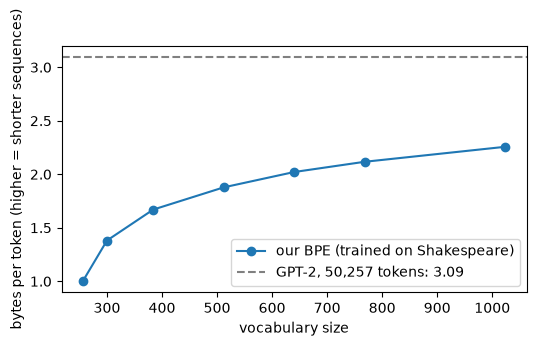

{256: 1.0, 300: 1.38, 384: 1.67, 512: 1.88, 640: 2.02, 768: 2.12, 1024: 2.26}


In [9]:
nbytes = len(test_text.encode())
sizes = [256, 300, 384, 512, 640, 768, 1024]
bpt = []
for V in sizes:
    sub = {t: i for t, i in ranks.items() if i < V}
    bpt.append(nbytes / len(encode(test_text, sub)))
gpt2_bpt = nbytes / len(gpt2.encode(test_text))

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(sizes, bpt, marker="o", label="our BPE (trained on Shakespeare)")
ax.axhline(gpt2_bpt, ls="--", c="gray", label=f"GPT-2, 50,257 tokens: {gpt2_bpt:.2f}")
ax.set_xlabel("vocabulary size"); ax.set_ylabel("bytes per token (higher = shorter sequences)")
ax.legend(); plt.show()
print(dict(zip(sizes, [round(x, 2) for x in bpt])))

Returns diminish: the first merges save a lot, later ones little. A bigger vocabulary shortens sequences but makes the embedding and output matrices bigger (vocab x d_model parameters; module 1 measured 38.6M for GPT-2) and leaves rare tokens with few training examples.

## 8. Awkward strings
Whitespace, case and digits change how text is split. Compare GPT-2, GPT-4 and GPT-4o (`o200k_base`) tokenizers:

In [10]:
o200k = tiktoken.get_encoding("o200k_base")
def pieces(enc, s):
    return [enc.decode_single_token_bytes(i).decode("utf-8", "replace") for i in enc.encode(s)]

for s in [" hello", "hello", "Hello", "HELLO", "1234567", " 2024", "strawberry"]:
    print(f"{s!r:14}", "GPT-2:", pieces(gpt2, s), "| GPT-4:", pieces(cl, s), "| GPT-4o:", pieces(o200k, s))

' hello'       GPT-2: [' hello'] | GPT-4: [' hello'] | GPT-4o: [' hello']
'hello'        GPT-2: ['hello'] | GPT-4: ['hello'] | GPT-4o: ['hello']
'Hello'        GPT-2: ['Hello'] | GPT-4: ['Hello'] | GPT-4o: ['Hello']
'HELLO'        GPT-2: ['HE', 'LL', 'O'] | GPT-4: ['HEL', 'LO'] | GPT-4o: ['HEL', 'LO']
'1234567'      GPT-2: ['123', '45', '67'] | GPT-4: ['123', '456', '7'] | GPT-4o: ['123', '456', '7']
' 2024'        GPT-2: [' 2024'] | GPT-4: [' ', '202', '4'] | GPT-4o: [' ', '202', '4']
'strawberry'   GPT-2: ['st', 'raw', 'berry'] | GPT-4: ['str', 'aw', 'berry'] | GPT-4o: ['st', 'raw', 'berry']


Notice: `' hello'` and `'hello'` are different tokens; `HELLO` shatters; numbers are chopped into arbitrary chunks, and the model never sees `strawberry` as letters. These quirks explain many LLM failures on spelling, letter counting and arithmetic.

## 9. Same sentence, different languages
Token counts for roughly the same meaning, in three real tokenizers.

In [11]:
sents = {
    "English":  "The weather is nice today, so let's go for a walk in the park.",
    "German":   "Das Wetter ist heute schön, also lass uns im Park spazieren gehen.",
    "Spanish":  "El tiempo es agradable hoy, así que vamos a pasear por el parque.",
    "Hindi":    "आज मौसम अच्छा है, इसलिए चलो पार्क में टहलने चलते हैं।",
    "Japanese": "今日は天気がいいので、公園を散歩しましょう。",
}
encs = {"GPT-2": gpt2, "GPT-4": cl, "GPT-4o": o200k}
print(f"{'':10}" + "".join(f"{n:>8}" for n in encs))
for lang, s in sents.items():
    print(f"{lang:10}" + "".join(f"{len(e.encode(s)):8d}" for e in encs.values()))

             GPT-2   GPT-4  GPT-4o
English         17      17      16
German          24      18      15
Spanish         25      19      16
Hindi           83      55      16
Japanese        30      26      14


Newer vocabularies, trained on more multilingual data, narrow the gap a lot. But a token budget is also a context-window and price budget, so the language you write in affects both (Petrov et al. 2023; Ahia et al. 2023).

## Exercises
1. Train `train_bpe` on Python source (e.g. concatenate the `.py` files under `.venv/lib/python3.12/site-packages/regex`) and compare the first 30 merges with Shakespeare's. What changes?
2. Our `encode_piece` merges the lowest-id pair. Implement the other definition (replay the merges in the order they were learned) and check that both agree on the test set. Can you construct a case where they would differ?
3. `train_bpe` recounts all pairs after every merge. Make it incremental (update counts only for words containing the merged pair) and measure the speed-up. (This is how Sennrich et al.'s reference implementation works.)
4. Using `gpt2._mergeable_ranks`, find the longest tokens in GPT-2's vocabulary and the share of tokens that begin with a space. What does that say about the training data?
5. Find three English words that GPT-2 splits into 4+ tokens, and three strings that cost very different numbers of tokens with and without a leading space.